# Baseline Model for SDSS Astronomical Object Classification

This notebook closely follows the methodology from `algorithms-16-00293.pdf`. It includes a specialized Exploratory Data Analysis (EDA) process and evaluates the exact Random Forest model design on all three datasets used in the paper: **SDSS DR14, DR16, and DR17**.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from IPython.display import display
import os

## 2. Load Datasets

In [2]:
datasets = {
    'DR14': pd.read_csv('Datasets/DR14.csv'),
    'DR16': pd.read_csv('Datasets/DR16.csv'),
    'DR17': pd.read_csv('Datasets/DR17.csv')
}

for name, df in datasets.items():
    print(f'{name} shape: {df.shape}')

DR14 shape: (10000, 18)
DR16 shape: (100000, 18)
DR17 shape: (100000, 18)


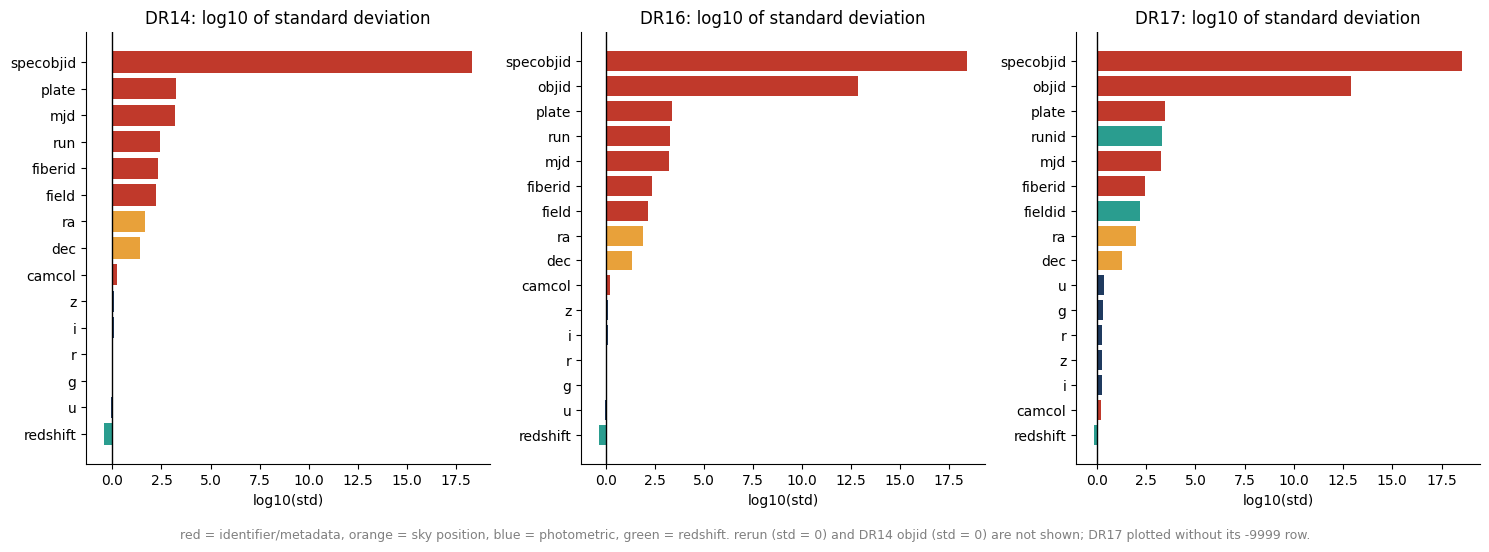

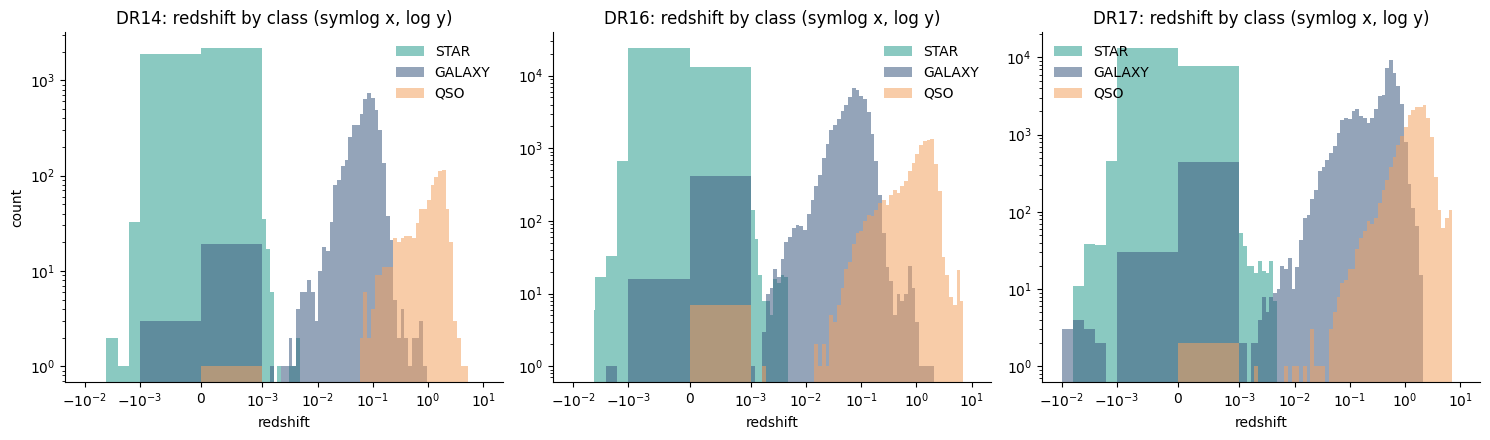

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mutual_info_score

def canon(df):
    """Same column names for all releases (objid, specobjid, camcol, mjd, ...)."""
    d = df.copy()
    d.columns = [c.lower().replace('_', '') for c in d.columns]
    d = d.rename(columns={'alpha': 'ra', 'delta': 'dec'})
    return d

D = {k: canon(v) for k, v in datasets.items()}
IDS  = ['objid','run','rerun','camcol','field','specobjid','plate','mjd','fiberid']
POS  = ['ra','dec']
PHOT = ['u','g','r','i','z']

# ---- Figure 4: log10 of the standard deviation of every attribute ----
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (name, d) in zip(axes, D.items()):
    d = d[d['u'] > -9000]
    sd = d.drop(columns='class').std(numeric_only=True)
    sd = sd[sd > 0].sort_values()
    col = ['#C0392B' if c in IDS else '#E8A13A' if c in POS else
           '#1F3A5F' if c in PHOT else '#2A9D8F' for c in sd.index]
    ax.barh(sd.index, np.log10(sd), color=col)
    ax.axvline(0, color='k', lw=1)
    ax.set_title(f'{name}: log10 of standard deviation')
    ax.set_xlabel('log10(std)')
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
fig.text(0.5, 0.01, 'red = identifier/metadata, orange = sky position, blue = photometric, green = redshift. '
         'rerun (std = 0) and DR14 objid (std = 0) are not shown; DR17 plotted without its -9999 row.',
         ha='center', fontsize=9, color='gray')
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig('outputs/figures/E2_feature_scales_measured.png', dpi=200)
plt.show()

# ---- Figure 5: redshift by class (symlog x, log y) ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, d) in zip(axes, D.items()):
    bins = np.concatenate([-np.logspace(-2, -3, 6), [0], np.logspace(-3, 1, 60)])
    bins = np.unique(np.concatenate([[d['redshift'].min() - 1e-9], bins, [d['redshift'].max() + 1e-9]]))
    for cls, colr in (('STAR', '#2A9D8F'), ('GALAXY', '#3D5A80'), ('QSO', '#F4A261')):
        ax.hist(d.loc[d['class'] == cls, 'redshift'], bins=bins, alpha=0.55, color=colr, label=cls)
    ax.set_xscale('symlog', linthresh=1e-3); ax.set_yscale('log')
    ax.set_title(f'{name}: redshift by class (symlog x, log y)')
    ax.set_xlabel('redshift'); ax.legend(frameon=False)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axes[0].set_ylabel('count')
plt.tight_layout()
plt.savefig('outputs/figures/E3_redshift_by_class_measured.png', dpi=200)
plt.show()

In [ ]:
rows = []
for name, d in D.items():
    d = d[d['u'] > -9000]
    sp = d[PHOT].corr(method='spearman').values
    off = sp[np.triu_indices(5, 1)]
    h = mutual_info_score(d['class'], d['class'])
    row = {'Dataset': name,
           'Spearman ugriz min': off.min(), 'Spearman ugriz max': off.max(),
           'skew redshift': stats.skew(d['redshift']),
           'excess kurt redshift': stats.kurtosis(d['redshift']),
           'skew r': stats.skew(d['r']), 'H(class) nats': h}
    for c in ('plate', 'mjd', 'fiberid'):
        mi = mutual_info_score(d[c], d['class'])
        row[f'MI({c}) nats'] = mi
        row[f'MI({c}) % of H'] = 100 * mi / h
    rows.append(row)
display(pd.DataFrame(rows).round(2).set_index('Dataset').T)

# standard deviations quoted in the text (full files, sentinel row included)
sd_tab = pd.DataFrame({n: d[['objid','specobjid','redshift','u','g','r','i','z']].std()
                       for n, d in D.items()})
display(sd_tab.map(lambda v: f'{v:.3g}'))

Dataset,DR14,DR16,DR17
Spearman ugriz min,0.51,0.50,0.50
Spearman ugriz max,0.99,0.99,0.98
skew redshift,4.27,4.05,2.52
excess kurt redshift,20.54,21.31,9.97
skew r,-0.02,-0.14,-0.51
H(class) nats,0.92,0.95,0.96
MI(plate) nats,0.43,0.46,0.34
MI(plate) % of H,46.85,48.80,35.41
MI(mjd) nats,0.41,0.34,0.22
MI(mjd) % of H,44.07,35.63,22.51


,DR14,DR16,DR17
objid,0,7.26e+12,8.44e+12
specobjid,2.01e+18,2.49e+18,3.32e+18
redshift,0.389,0.438,0.731
u,0.829,0.832,31.8
g,0.945,0.986,31.8
r,1.07,1.13,1.85
i,1.14,1.21,1.76
z,1.2,1.28,31.7


## 3. Specialized Exploratory Data Analysis (EDA)


EDA for DR14
Total Missing Values (NaNs): 0
Sentinel Values (<-9000 in u, g, z): 0

Class Distribution:
 class
GALAXY    4998
STAR      4152
QSO        850

Imbalance Ratio (IR): 5.88

Paper Class Counts for DR14: GALAXY 4998, QSO 850, STAR 4152

Scale Disparity Check:
              objid            ra           dec             u             g             r             i             z           run    rerun        camcol         field     specobjid      redshift         plate           mjd       fiberid
count  1.000000e+04  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000  10000.0  10000.000000  10000.000000  1.000000e+04  10000.000000  10000.000000  10000.000000  10000.000000
mean   1.237650e+18    175.529987     14.836148     18.619355     17.371931     16.840963     16.583579     16.422833    981.034800    301.0      3.648700    302.380100  1.645022e+18      0.143726   1460.986400  52943.533300    353.069400
std    0.000

d:\GitHub\Machine Learning Assignment\.venv\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


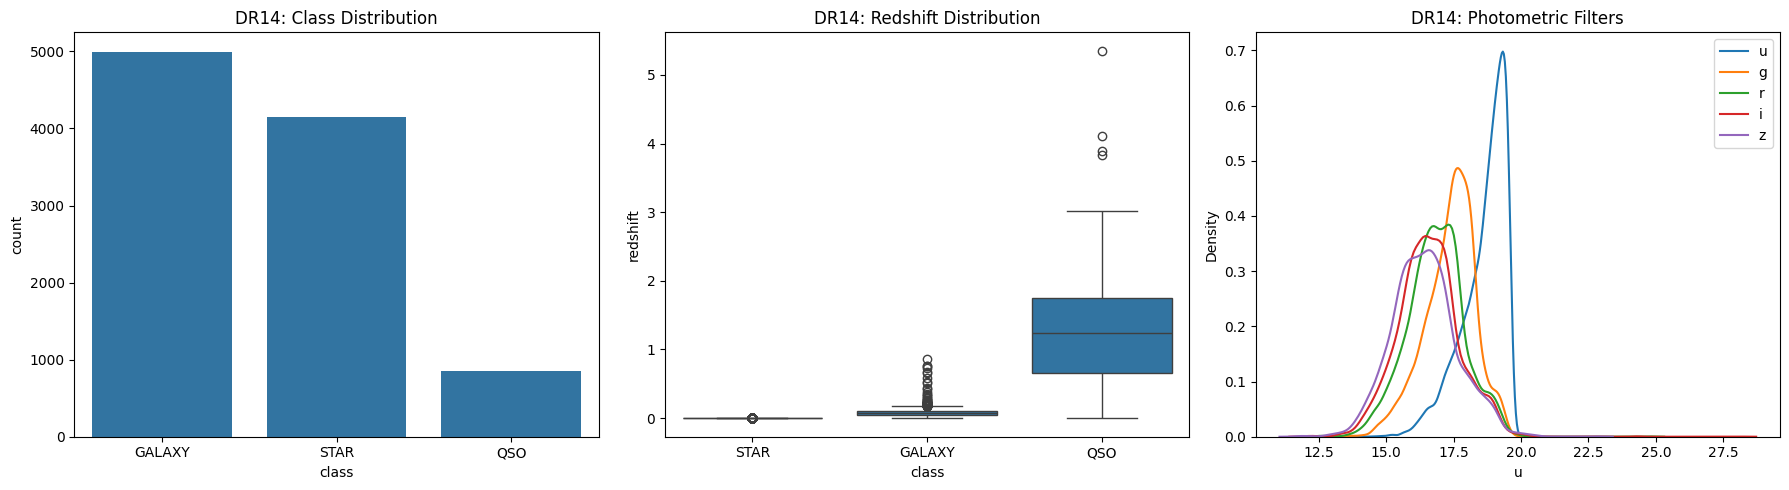


EDA for DR16
Total Missing Values (NaNs): 0
Sentinel Values (<-9000 in u, g, z): 0

Class Distribution:
 class
GALAXY    51323
STAR      38096
QSO       10581

Imbalance Ratio (IR): 4.85

Scale Disparity Check:
              objid             ra            dec              u              g              r              i              z            run     rerun         camcol          field     specobjid       redshift          plate            mjd        fiberid
count  1.000000e+05  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.0  100000.000000  100000.000000  1.000000e+05  100000.000000  100000.000000  100000.000000  100000.000000
mean   1.237663e+18     177.512888      25.052056      18.637915      17.407128      16.881676      16.625534      16.467087    3978.727640     301.0       3.274010     187.243080  2.913905e+18       0.170621    2587.984270   53913.908690     341.699080
std    7.264931e+12      7

d:\GitHub\Machine Learning Assignment\.venv\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


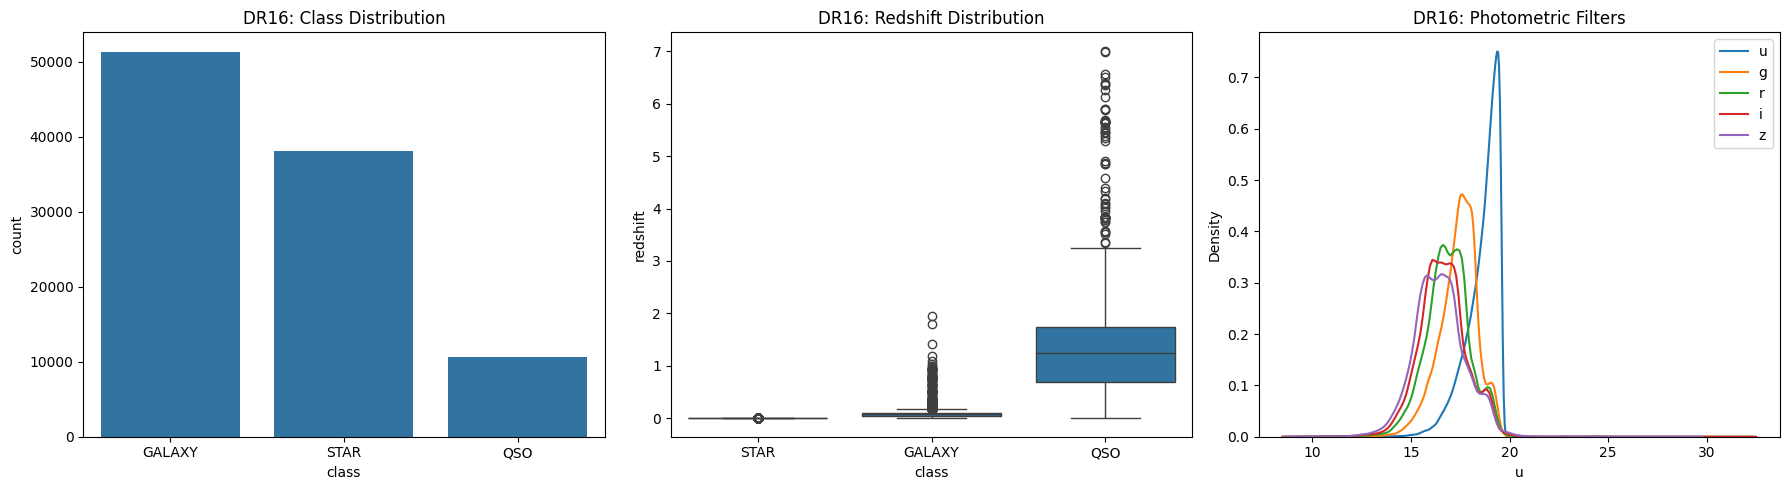


EDA for DR17
Total Missing Values (NaNs): 0
Sentinel Values (<-9000 in u, g, z): 3

Class Distribution:
 class
GALAXY    59445
STAR      21594
QSO       18961

Imbalance Ratio (IR): 3.14

Scale Disparity Check:
             obj_ID          alpha          delta              u              g              r              i              z         run_ID  rerun_ID        cam_col       field_ID   spec_obj_ID       redshift          plate            MJD       fiber_ID
count  1.000000e+05  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.0  100000.000000  100000.000000  1.000000e+05  100000.000000  100000.000000  100000.000000  100000.000000
mean   1.237665e+18     177.629117      24.135305      21.980468      20.531387      19.645762      19.084854      18.668810    4481.366060     301.0       3.511610     186.130520  5.783882e+18       0.576661    5137.009660   55588.647500     449.312740
std    8.438560e+12      9

d:\GitHub\Machine Learning Assignment\.venv\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


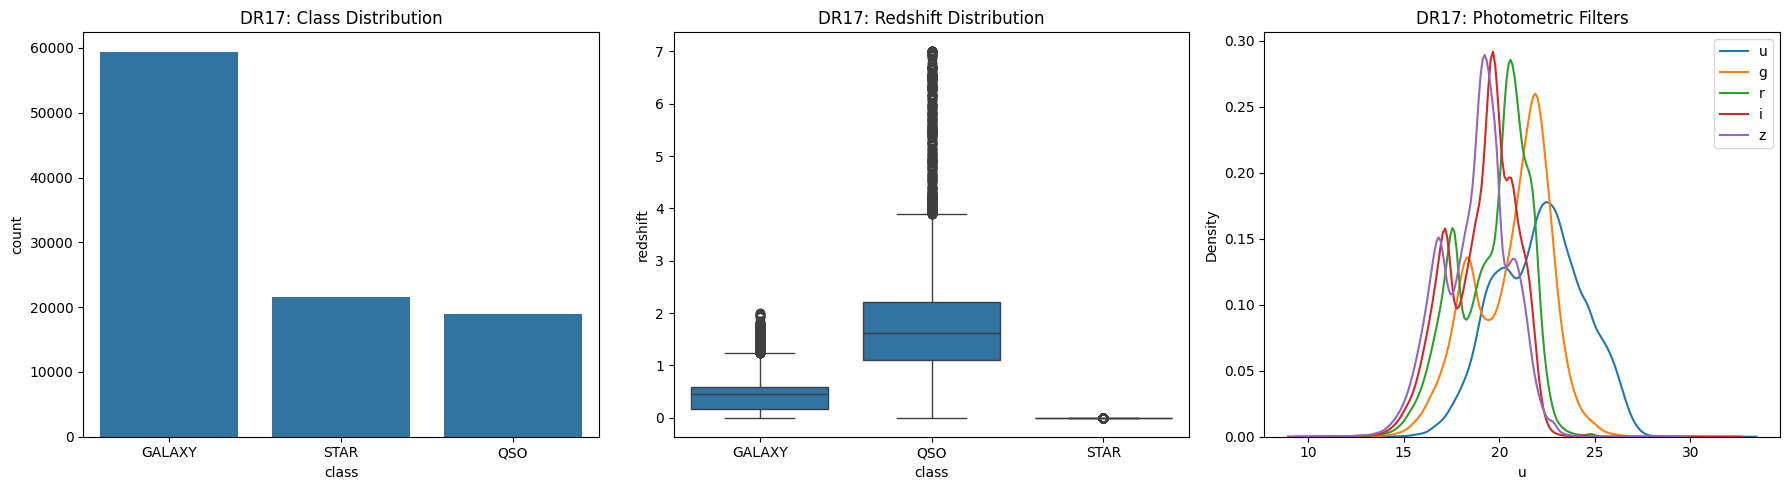

In [5]:
def perform_eda(name, df):
    print(f'\n' + '='*40 + f'\nEDA for {name}\n' + '='*40)

    # Missing values and Sentinel check
    missing = df.isnull().sum().sum()
    print(f'Total Missing Values (NaNs): {missing}')
    
    sentinel_count = (df[['u','g','z']] < -9000).sum().sum()
    print(f'Sentinel Values (<-9000 in u, g, z): {sentinel_count}')

    # Class distribution & Imbalance Ratio
    class_counts = df['class'].value_counts()
    print('\nClass Distribution:\n', class_counts.to_string())
    IR = class_counts.max() / class_counts.min()
    print(f'\nImbalance Ratio (IR): {IR:.2f}\n')
    if name == 'DR14':
        print('Paper Class Counts for DR14: GALAXY 4998, QSO 850, STAR 4152\n')

    # EDA Checks: Scale disparity, correlations, distributions
    print("Scale Disparity Check:")
    numeric_df = df.select_dtypes(include=[np.number])
    print(numeric_df.describe().to_string())
    print("\nLog10 of Standard Deviations:")
    print(np.log10(numeric_df.std()).to_string())
    print("\nClass-Level Medians:")
    print(df.groupby('class')[['u','g','r','i','z','redshift']].median().to_string())
    print("\n")

    # Visualizations
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Class Distribution
    sns.countplot(data=df, x='class', order=class_counts.index, ax=axes[0])
    axes[0].set_title(f'{name}: Class Distribution')

    # 2. Redshift Distribution
    sns.boxplot(data=df, x='class', y='redshift', ax=axes[1])
    axes[1].set_title(f'{name}: Redshift Distribution')

    # 3. Filter Distributions (u, g, r, i, z) with filtering
    df_filtered = df[df['u'] > -9000]
    for band in ['u', 'g', 'r', 'i', 'z']:
        sns.kdeplot(data=df_filtered, x=band, label=band, ax=axes[2], common_norm=False)
    axes[2].set_title(f'{name}: Photometric Filters')
    axes[2].legend()

    plt.tight_layout()
    plt.show()

for name, df in datasets.items():
    perform_eda(name, df)

## 4. Baseline Model Definition & Evaluation

Following the exact specifications in the paper:
- **Classifier**: Random Forest
- **Number of trees**: 100
- **Depth**: Maximum possible (None)
- **Number of samples (min_samples_split)**: 2
- **Number of attributes to consider**: sqrt(features)
- **Bootstrap**: True
- **Validation**: 80-20 Hold-out (Stratified)

We run seeds 1-10 to calculate the Mean ± SD.

In [ ]:
def get_metrics_from_cm(cm):
    """Calculate accuracy, binary metrics, and macro metrics from confusion matrix."""
    total = cm.sum()
    acc = np.trace(cm) / total if total > 0 else 0
    
    # Macro metrics over the 3 classes
    recalls = []
    specificities = []
    for i in range(3):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = total - TP - FN - FP
        
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        spec = TN / (FP + TN) if (FP + TN) > 0 else 0
        recalls.append(recall)
        specificities.append(spec)
        
    sens_macro = np.mean(recalls)
    spec_macro = np.mean(specificities)
    
    paper_ba = (sens_macro + spec_macro) / 2
    
    return {
        'Accuracy': acc,
        'Macro-Recall': sens_macro,
        'Specificity (Macro)': spec_macro,
        'Paper-style BA': paper_ba
    }

def evaluate_baseline_model(name, df, drop_identifiers=False, seeds=range(1, 11)):
    # match case-insensitively
    identifiers = {'objid', 'obj_id', 'run', 'run_id', 'rerun', 'rerun_id', 'camcol', 'cam_col',
                   'field', 'field_id', 'specobjid', 'spec_obj_id', 'plate', 'mjd', 'fiberid', 'fiber_id'}
    
    if drop_identifiers:
        # Drop identifiers that exist in the dataframe
        to_drop = [c for c in df.columns if c.lower() in identifiers] + ['class']
        X = df.drop(columns=to_drop)
        print(f'  {name}: {X.shape[1]} features kept: {list(X.columns)}')
        assert X.shape[1] == 8, f'{name}: expected 8 features, got {X.shape[1]}'
    else:
        X = df.drop(columns=['class'])
        
    y = df['class']
    
    all_metrics = []
    cm_sum = np.zeros((3, 3))
    
    for seed in seeds:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20, random_state=seed, stratify=y
        )

        rf_model = RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_split=2,
            max_features='sqrt',
            bootstrap=True,
            random_state=seed,
            n_jobs=-1
        )
        rf_model.fit(X_train, y_train)
        y_pred = rf_model.predict(X_test)
        
        cm = confusion_matrix(y_test, y_pred, labels=['GALAXY', 'QSO', 'STAR'])
        cm_sum += cm
        
        metrics = get_metrics_from_cm(cm)
        all_metrics.append(metrics)
    
    # Calculate means and stds
    metrics_df = pd.DataFrame(all_metrics)
    means = metrics_df.mean().to_dict()
    stds = metrics_df.std().to_dict()
    
    res = {}
    for k in means:
        res[k] = f"{means[k]:.4f} ± {stds[k]:.4f}"
        res[k + '_raw'] = means[k]
        
    avg_cm = cm_sum / len(seeds)
    return res, avg_cm

## 5. Results across all Datasets

In [ ]:
results = []
results_no_id = []
confusion_matrices = {}

# Run with identifiers (Baseline)
for name, df in datasets.items():
    print(f'Training and evaluating on {name} (With Identifiers, 10 seeds)...')
    res, cm = evaluate_baseline_model(name, df, drop_identifiers=False)
    
    results.append({
        'Dataset': name,
        'Accuracy': res['Accuracy_raw'],
        'Macro-Recall': res['Macro-Recall_raw'],
        'Specificity (Macro)': res['Specificity (Macro)_raw'],
        'Paper-style BA': res['Paper-style BA_raw'],
        'Accuracy (±SD)': res['Accuracy'],
        'Macro-Recall (±SD)': res['Macro-Recall'],
        'Specificity (Macro) (±SD)': res['Specificity (Macro)'],
        'Paper-style BA (±SD)': res['Paper-style BA']
    })
    confusion_matrices[name] = cm

# Run without identifiers
for name, df in datasets.items():
    print(f'Training and evaluating on {name} (Without Identifiers, 10 seeds)...')
    res, _ = evaluate_baseline_model(name, df, drop_identifiers=True)
    results_no_id.append({
        'Dataset': name + ' (No Identifiers)',
        'Accuracy': res['Accuracy_raw'],
        'Macro-Recall': res['Macro-Recall_raw'],
        'Specificity (Macro)': res['Specificity (Macro)_raw'],
        'Paper-style BA': res['Paper-style BA_raw']
    })

results_df = pd.DataFrame(results)
results_no_id_df = pd.DataFrame(results_no_id)

csv_path = os.path.join('phase1_reproducibility', 'data', 'paper_tables_2_3_4.csv')
if os.path.exists(csv_path):
    paper_df = pd.read_csv(csv_path)
    
    # Extract Random Forest metrics
    paper_rf = paper_df[['dataset', 'metric', 'RandomForest']].copy()
    paper_rf = paper_rf.pivot(index='dataset', columns='metric', values='RandomForest').reset_index()
    paper_rf = paper_rf.rename(columns={
        'dataset': 'Dataset',
        'sensitivity': 'Macro-Recall',
        'specificity': 'Specificity (Macro)',
        'balanced_accuracy': 'Paper-style BA'
    })
    
    # Paper's accuracy cells recomputed from its confusion matrices
    acc_map = {'DR14': 0.9885, 'DR16': 0.9901, 'DR17': 0.9808}
    paper_rf['Accuracy'] = paper_rf['Dataset'].map(acc_map)
    
    paper_rf['Dataset'] = paper_rf['Dataset'] + ' (Paper RF)'
    
    results_df_copy = results_df[['Dataset', 'Accuracy', 'Macro-Recall', 'Specificity (Macro)', 'Paper-style BA']].copy()
    results_df_copy['Dataset'] = results_df_copy['Dataset'] + ' (Notebook RF)'
    
    combined_df = pd.concat([results_df_copy, paper_rf, results_no_id_df], ignore_index=True)
    
    combined_df['SortKey'] = combined_df['Dataset'].str[:4]
    
    def custom_sort(x):
        if 'Notebook RF' in x: return 1
        elif 'Paper RF' in x: return 2
        else: return 3
        
    combined_df['Order'] = combined_df['Dataset'].apply(custom_sort)
    combined_df = combined_df.sort_values(by=['SortKey', 'Order']).drop(columns=['SortKey', 'Order']).reset_index(drop=True)
    
    print('\nSide-by-Side Comparison: Notebook RF vs Paper RF vs Notebook (No Identifiers)')
    display(combined_df)
    
    print('\nDetailed Notebook RF Results (10 seeds mean ± SD):')
    display(results_df[['Dataset', 'Accuracy (±SD)', 'Macro-Recall (±SD)', 'Specificity (Macro) (±SD)', 'Paper-style BA (±SD)']])
else:
    display(results_df)

Training and evaluating on DR14 (With Identifiers, 10 seeds)...
Training and evaluating on DR16 (With Identifiers, 10 seeds)...
Training and evaluating on DR17 (With Identifiers, 10 seeds)...
Training and evaluating on DR14 (Without Identifiers, 10 seeds)...
  DR14: 8 features kept: ['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift']
Training and evaluating on DR16 (Without Identifiers, 10 seeds)...
  DR16: 8 features kept: ['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift']
Training and evaluating on DR17 (Without Identifiers, 10 seeds)...
  DR17: 8 features kept: ['alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift']

Side-by-Side Comparison: Notebook RF vs Paper RF vs Notebook (No Identifiers)


,Dataset,Accuracy,Macro-Recall,Specificity (Macro),Paper-style BA
0,DR14 (Notebook RF),0.987500,0.968197,0.992694,0.980446
1,DR14 (Paper RF),0.988500,0.979200,0.994000,0.986600
2,DR14 (No Identifiers),0.988400,0.970432,0.993158,0.981795
3,DR16 (Notebook RF),0.991025,0.979366,0.994536,0.986951
4,DR16 (Paper RF),0.990100,0.978300,0.994000,0.986100
5,DR16 (No Identifiers),0.991555,0.980294,0.994844,0.987569
6,DR17 (Notebook RF),0.978950,0.972712,0.986018,0.979365
7,DR17 (Paper RF),0.980800,0.975600,0.987400,0.981500
8,DR17 (No Identifiers),0.978575,0.971799,0.985628,0.978713



Detailed Notebook RF Results (10 seeds mean ± SD):


,Dataset,Accuracy (±SD),Macro-Recall (±SD),Specificity (Macro) (±SD),Paper-style BA (±SD)
0,DR14,0.9875 ± 0.0012,0.9682 ± 0.0052,0.9927 ± 0.0008,0.9804 ± 0.0030
1,DR16,0.9910 ± 0.0007,0.9794 ± 0.0015,0.9945 ± 0.0004,0.9870 ± 0.0009
2,DR17,0.9789 ± 0.0006,0.9727 ± 0.0010,0.9860 ± 0.0004,0.9794 ± 0.0007


## 6. Confusion Matrices

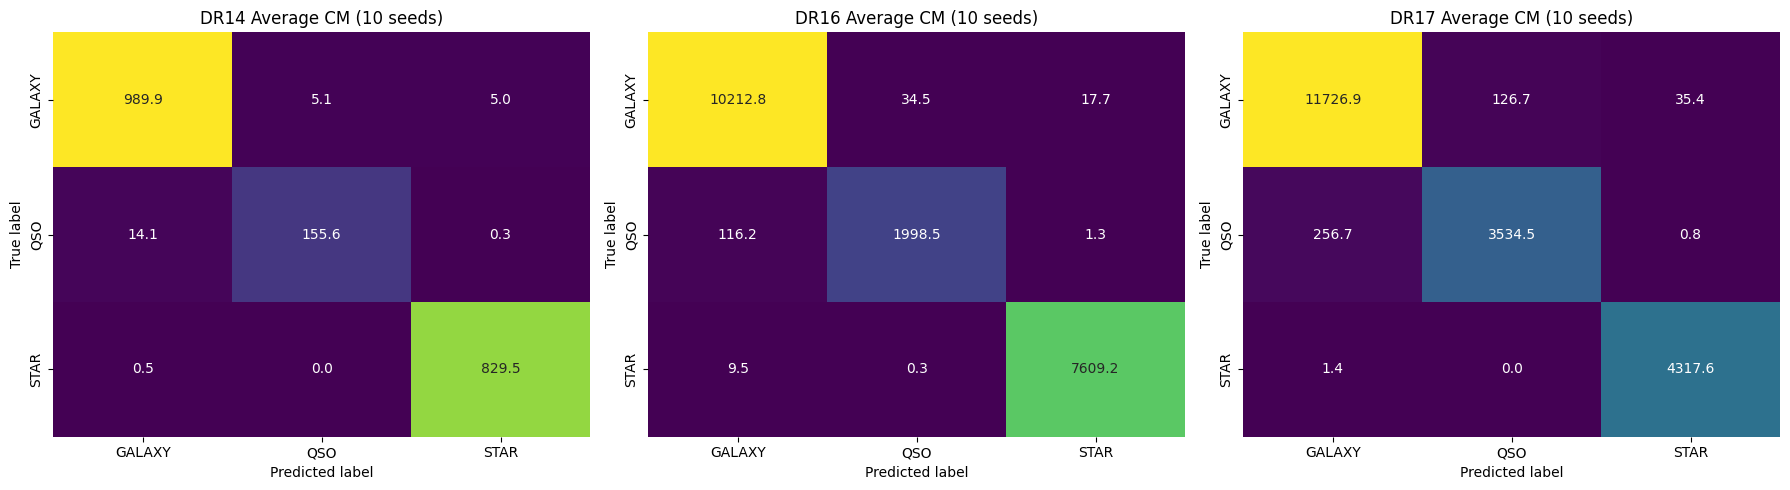

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, name in enumerate(['DR14', 'DR16', 'DR17']):
    sns.heatmap(confusion_matrices[name], annot=True, fmt='.1f', cmap='viridis', 
                xticklabels=['GALAXY', 'QSO', 'STAR'], 
                yticklabels=['GALAXY', 'QSO', 'STAR'], 
                ax=axes[i], cbar=False)
    axes[i].set_title(f'{name} Average CM (10 seeds)')
    axes[i].set_xlabel('Predicted label')
    axes[i].set_ylabel('True label')

plt.tight_layout()
plt.show()